# The public 0.684 notebook, explained

Source: Kaggle notebook **"Name That LLM | Deep Forensic EDA with Analogie"** by evgendvorkin (public).

It has two halves that have nothing to do with each other:

| Part | What it is | Who made it |
|---|---|---|
| **Part I: sections 01 to 05** | An EDA of `train.csv` (length, punctuation, one prompt answered by 18 models, the "validation trap") | The author |
| **Part II: sections 06 to 18** | **Inference only**: it loads weights that other people trained and published, and combines them. It is a copy of the public **0.684** ensemble ("Clean LoRA + Qwen3-Embedding") | Other Kagglers, credited in section 20 |

So the score comes from Part II. **All the large models were trained elsewhere** and uploaded as Kaggle datasets; this notebook runs them on the test set and blends the answers. Only small, fast models are fitted while it runs (the "stylegram" LinearSVC and other members of the complementary stack, section 16, and the Gaussian group heads, section 09).

How to read this notebook: each section says **what the step does**, then **the maths**, then **the code** (short excerpts from their notebook, or a small re-implementation that runs here on CPU), and finally **what it means for us**.

In [1]:
import re, itertools, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
warnings.filterwarnings("ignore")
ROOT = "../"
train = pd.read_csv(ROOT + "data/train.csv")
FAMILIES = ["claude", "gemini", "gpt", "glm", "kimi", "qwen"]
FAM_COLOR = dict(zip(FAMILIES, ["#2a78d6", "#eb6834", "#1baf7a", "#c08400", "#e87ba4", "#008300"]))
fam = lambda m: next(f for f in FAMILIES if m.startswith(f))
MODELS = sorted(train.model.unique(), key=lambda m: (FAMILIES.index(fam(m)), m))
SEQ = LinearSegmentedColormap.from_list("seq", ["#f5f8fc", "#b9d3f2", "#5b93db", "#1c5cab", "#0b2f5e"])
DIV = LinearSegmentedColormap.from_list("div", ["#1c5cab", "#86b6ef", "#ecebe6", "#f3a17f", "#b8431a"])
plt.rcParams.update({"figure.facecolor": "white", "axes.facecolor": "white", "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False})
def colour_labels(ax, axis="y"):
    for lab in (ax.get_yticklabels() if axis == "y" else ax.get_xticklabels()):
        t = lab.get_text()
        if any(t.startswith(f) for f in FAMILIES): lab.set_color(FAM_COLOR[fam(t)]); lab.set_fontweight("bold")
print(train.shape, train.prompt_id.nunique(), "prompts")

(2699, 4) 150 prompts


## A. The facts in tables

### A1. The 0.684 pipeline at a glance (from the command in their section 17)

| # | Component | Base model (size) | What it reads | Weight in the blend |
|---|---|---|---|---|
| 1 | `q14v5` | Qwen3-14B base (first 27 layers kept) | multi-depth LoRA classifier, **6 adapters** (5 folds + 1 full fit) averaged | 3.0 (+ Gaussian head 0.70, + centred "twin" head) |
| 2 | `q8v5` | Qwen3-8B base (24 layers) | same, 6 adapters | 2.0 (+ Gaussian head 0.44, + twin) |
| 3 | `ll8v5` | Llama-3.1-8B base | same, 6 adapters | 1.0 (+ twin) |
| 4 | `n14b_clean` | Qwen3-14B base | 2 different adapters mixed 0.72 / 0.28 | 2.5 (+ twin) |
| 5 | `q25_14` | Qwen2.5-14B | 1 adapter | 1.0 (+ twin) |
| 6 | `deb` | DeBERTa-v3-large (encoder) | fine-tuned classifier | 1.0 |
| 7 | complementary stack | a **second ensemble** (section 16): its biggest part is "stylegram", a LinearSVC on style n-grams fitted while the notebook runs on train.csv + Open Pool prompts answered by 12+ models, plus smaller weights for several LoRA readers, encoders (DeBERTa, ELECTRA, ...), token-attention heads, Gaussian heads and family gates | | 15% (mixed in probability space) |
| 8 | GSQ | Qwen3.8-27B (quantised) | its own fitted classifier | 3% (probability space) |
| 9 | native expert | Qwen3-Embedding-8B | 5 fold heads, calibrated | 40% (log space, last step) |
| 10 | grouping | Qwen3-Embedding-8B cosine | clusters of related test texts, max 18, cosine >= 0.70 | used by the twin and Gaussian heads and by the native centring |
| 11 | partial Sinkhorn | | class balancing | strength 0.30, target 65% current mix + 35% train mix |

**Switched off in the 0.684 command** (the code is in the notebook, but the run does not use it):
- their **ATLAS** (section 10): `--atlas_mode` is never passed, so it stays at its default `off`.
- the **sparse prefit readouts** (section 12: LinearSVC, TF-IDF, "distort"): `--svc_w 0 --tfidf_w 0 --distort_w 0`. They are only loaded once in the quick public-test path as a smoke test.

### A2. Their release history (section 19)

| Release | Public LB | What changed |
|---|---|---|
| V10 | 0.631 | early multi-model reproduction |
| V14 | 0.661 | better ensemble, Open Pool correction |
| V15 / V16 | 0.668 | stable Open Pool, their EDA added |
| V17 | 0.669 | someone else's Sinkhorn setting |
| V18 | 0.670 | DeBERTa ensemble |
| V19 | 0.673 | ModernBERT blend |
| V24 / V25 | 0.680 / 0.681 | Qwen3-Embedding native expert + LoRA parent |
| V26 | 0.682 | GSQ (27B) + Sinkhorn target mix |
| V27 | 0.683 | "Sovereign Titan Apex" |
| current | 0.684 | clean Qwen3-14B adapters 0.72 / 0.28, native 40%, GSQ 3% |

Every step after 0.631 is **someone else's public component** being added. The whole Kaggle community has been stacking public pieces.

### A3. Datasets attached to their notebook (from `kernel-metadata.json`)

| Dataset | What it is (from its name and use) |
|---|---|
| `crtproduction/name-that-llm-open-pool` | the community **Open Pool** (the same one our Pool 60k / 92k come from). Used by the complementary stack: it keeps only Open Pool prompts answered by **12 or more** models (Kaggle-like structure), 30 to 300 words, and trains on them with a total weight equal to train.csv's. (Section 07 also writes a `match_weight` sample, but the 0.684 command never passes it to `infer.py`.) |
| `dhruvtibarewal/nlm-matched-clean` | a cleaned "matched" set; only its per-model counts are used here, to decide how many Open Pool rows to draw per model |
| `prvsiyan/prvsiyans-extended-name-that-llm-dataset` | **hostlike**, the same dataset we compared |
| `seyitkaangunes/ntl-extra-api-passages`, `abdullah1afify/ntl-generations`, `dophuchung/ntl-proxy-generations`, `lucasboesen/ntl-free-proxy-generations` | other people's own generations from the 18 models (extra training text) |
| `dhruvtibarewal/nlm-l24-adapters(-v5)`, `nuridudak/ntl-q14-lora(-v4)`, `nishantdahal/ntl-two-stage-lora`, `zbigniewkirchner/ntl-qwen3-8b-lora-claude-head`, `pjmathematician/ultrabert-380m-ntl`, ... | **trained weights**: LoRA adapters and heads for the readers above |
| `lightningv08/...-inference-assets`, plus several kernel outputs (`lucasboesen/...`) | more trained weights and code |

**Which data trained which adapter is not visible here**: the training happened in other people's notebooks. What we can say: the pool of external text they draw from is the same Open Pool we use, plus several extra generation sets we have never used.

### A4. How they differ from us

| Topic | Public 0.684 | Us (v9 / v10, LB 0.580 / 0.581) |
|---|---|---|
| Biggest model | Qwen3-14B base (x2), Qwen2.5-14B, Qwen3.8-27B, Llama-3.1-8B, Qwen3-8B, Qwen3-Embedding-8B | Qwen3-4B base only |
| Readers in the blend | about 9 large neural readers | 4 Qwen-4B readers + SVM + LightGBM + our ATLAS |
| Same reader, several fits | yes: 5 fold adapters + 1 full fit per backbone, averaged | 1 full fit per reader (our seed test: +0.3 for 2 seeds, +0.5 for 3) |
| Reader design | mean-pooled hidden states at depths 2, 4, 6, 8, 12, 16, 20, 24, LayerNorm per depth, linear head | **the same design** (our `ms` head, same 8 depths) |
| Prompt-centred head | a second "twin" head trained on features with the group mean subtracted | we subtract a share of the cluster mean of the **log-probabilities** (centering 0.25) |
| Groups of test texts | Qwen3-Embedding cosine >= 0.70, size capped at 18 | TF-IDF clusters of about 9 texts, no cap |
| "One answer per model per prompt" | used inside a Gaussian group model (exact for groups of 2 to 3, approximate above) | tested on our simulator, not adopted (mean-field exclusion; hard assignment cost -3.5 on the LB) |
| Class balancing | partial Sinkhorn 0.30, target 65% current + 35% train mix | partial Sinkhorn 0.45 to a uniform target |
| External data | Open Pool + several other generation sets + hostlike (exact use per adapter unknown) | Open Pool (60k, 30k, 92k) + hostlike for one member |
| Who trained the weights | many people, weeks of GPU time | us, one RTX 4060 + Kaggle T4 quota |

### A5. Why so many Qwen models?

1. **Bigger is better here.** A 14B model has seen far more text and has a much richer internal picture of style. Their single 14B readers are likely well above our 4B on their own (we measured +1.6 OOF for 8B over 4B at the same data).
2. **Different models make different mistakes.** Averaging readers whose errors are not identical cancels part of the errors. Qwen3-14B, Qwen2.5-14B, Llama-3.1-8B and DeBERTa were pretrained on different data with different tokenisers, so they disagree in useful ways. The same is true, more weakly, for different adapters on one base model.
3. **Folds as free extra fits.** Training 5 fold adapters is needed anyway to measure out-of-fold scores; keeping all 5 (plus the full fit) and averaging them is like our seed averaging, but with 6 members instead of 1.
4. **Different "views" of one text.** The LoRA readers learn a classifier; the Qwen3-Embedding expert starts from a model built for similarity, the 27B GSQ is a very large reader. Each adds a slightly different view.

## B. Sections 01 to 04 in one paragraph each (you said these were clear)

- **01**: 150 prompts x 18 models, one pair missing (2,699 rows). A "chessboard".
- **02**: length per model, then **length minus the prompt's mean length**, which removes "this prompt asks for long answers".
- **03**: punctuation rates per 1,000 characters, prompt-centred, and **$\eta^2$** (eta squared): the share of a feature's variance that is explained by which model wrote it:
  $$\eta^2 = \frac{\sum_c n_c(\bar x_c - \bar x)^2}{\sum_i (x_i - \bar x)^2}$$
  between-model variance divided by total variance. 0 = the feature says nothing about the model, 1 = it decides it alone.
- **04**: one prompt, 18 answers side by side, as qualitative evidence.

## C. Section 05: the validation trap

### C1. What "validation" means here

We cannot score on the hidden test while we build a model, so we hide part of `train.csv`, train on the rest, and score on the hidden part. Doing this several times so every row is hidden once is **cross-validation (CV)**; the predictions for hidden rows are **out-of-fold (OOF)** predictions.

**The trap:** `train.csv` has 150 prompts, each answered by (almost) all 18 models. How you cut it matters:

| Split | What happens to one prompt | What the score measures |
|---|---|---|
| **A. Random** (`StratifiedKFold`) | its 18 answers are scattered: e.g. 12 in training, 6 in validation | how well you label an answer when you have **already seen other answers to the same prompt** |
| **B. Grouped by prompt** (`StratifiedGroupKFold`) | all 18 answers are on the same side | how well you label answers to **prompts you have never seen**, which is what the hidden test is |

Normally a random split **over**-estimates the score (it leaks the topic). The notebook's point is that here it can go the **other way**. Let us run their exact experiment.

### C2. Their code, line by line

```python
strategies = {
    "Random stratified": StratifiedKFold(n_splits=3, shuffle=True, random_state=42),
    "Prompt-grouped":    StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=42),
}
for name, cv in strategies.items():
    for tr_idx, va_idx in cv.split(texts, y, groups if name == "Prompt-grouped" else None):
        vectorizer = TfidfVectorizer(analyzer="char", ngram_range=(3, 4), min_df=3,
                                     max_features=22000, sublinear_tf=True)
        x_tr = vectorizer.fit_transform(texts[tr_idx])      # learn the vocabulary on the training part only
        x_va = vectorizer.transform(texts[va_idx])
        clf = LinearSVC(C=1.0, class_weight="balanced").fit(x_tr, y[tr_idx])
        oof[va_idx] = clf.predict(x_va)
```

- **char 3-4-gram TF-IDF**: every text becomes a vector with one number per 3- or 4-character snippet ("the", " th", "ing,"...). TF-IDF = how often the snippet appears in this text (log-damped by `sublinear_tf`), times how rare it is across texts. Rare snippets count more.
- **LinearSVC**: for each of the 18 models it learns a weight per snippet; a text's score for model $c$ is $s_c(x) = w_c \cdot x + b_c$, and the prediction is the model with the largest score.
- **Balanced accuracy**: the average over the 18 models of "share of that model's texts labelled correctly", so every model counts equally.

In [2]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold
from sklearn.svm import LinearSVC
from sklearn.metrics import balanced_accuracy_score, confusion_matrix
texts, y, groups = train.text.values, train.model.values, train.prompt_id.values
strategies = {"Random": StratifiedKFold(3, shuffle=True, random_state=42),
              "Grouped by prompt": StratifiedGroupKFold(3, shuffle=True, random_state=42)}
OOF, FOLDS, TRAINSEEN, CHANCE = {}, {}, {}, {}
for name, cv in strategies.items():
    oof = np.empty(len(train), dtype=object); seen = np.zeros(len(train), bool); chance = np.zeros(len(train)); folds = []
    for tr, va in cv.split(texts, y, groups if name != "Random" else None):
        vec = TfidfVectorizer(analyzer="char", ngram_range=(3, 4), min_df=3, max_features=22000, sublinear_tf=True,
                              dtype=np.float32)
        clf = LinearSVC(C=1.0, class_weight="balanced", max_iter=1500).fit(vec.fit_transform(texts[tr]), y[tr])
        oof[va] = clf.predict(vec.transform(texts[va]))
        folds.append(balanced_accuracy_score(y[va], oof[va]))
        # for the diagnosis below: did the PREDICTED model answer this same prompt inside the training part?
        tr_pairs = set(zip(groups[tr], y[tr]))
        seen[va] = [(g, p) in tr_pairs for g, p in zip(groups[va], oof[va])]
        # chance baseline: if a wrong prediction picked one of the other 17 models at random, how often would that
        # model have answered this prompt in the training part?
        per_prompt = {}
        for g_, m_ in tr_pairs: per_prompt.setdefault(g_, set()).add(m_)
        chance[va] = [len(per_prompt.get(g, set()) - {t}) / 17 for g, t in zip(groups[va], y[va])]
    OOF[name], FOLDS[name], TRAINSEEN[name], CHANCE[name] = oof, folds, seen, chance
    print(f"{name:18s} folds {np.round(folds, 3)}  OOF balanced accuracy {balanced_accuracy_score(y, oof):.3f}")

Random             folds [0.17  0.143 0.134]  OOF balanced accuracy 0.149


Grouped by prompt  folds [0.29  0.284 0.271]  OOF balanced accuracy 0.282


**What this shows:** the random split scores **0.149**, the prompt-grouped split **0.282**. The random split is almost **half** the grouped one, the opposite of the usual "random split leaks and looks too good". Every fold agrees (0.13 to 0.17 against 0.27 to 0.29), so it is not luck.

### C3. Why the random split can score **lower**: competing labels

Think about one validation text: prompt p017, written by `glm-5.3`. In the random split, about 12 of the other 17 answers to p017 are in the training part, **each with a different label** (and `glm-5.3`'s own answer is, by construction, not among them).

All answers to p017 share the topic snippets (the same names, numbers, technical words). The SVM learns: "p017's topic snippets go with `claude-opus-5`, `gpt-5.5`, `kimi-k3`, ..." (the models it saw for p017), **and never with `glm-5.3`**. So for our validation text the topic actively votes **against** the true model and **for** a model that answered the same prompt in training.

In the grouped split, p017 is entirely unseen: its topic snippets are new, carry no weight, and the decision rests on style alone.

**We can measure this directly**: for each wrong prediction, was the predicted model one that answered the same prompt in the training part? We compare with **chance**: about two thirds of the other 17 models have an answer to the same prompt in the training part, so a wrong guess picked at random would land on such a model about 66% of the time.

Random             wrong predictions: 2296  of which the predicted model answered the same prompt in the training part: 90.2%  (chance if wrong guesses were random: 66.4%)
Grouped by prompt  wrong predictions: 1938  of which the predicted model answered the same prompt in the training part: 0.0%  (chance if wrong guesses were random: 0.0%)


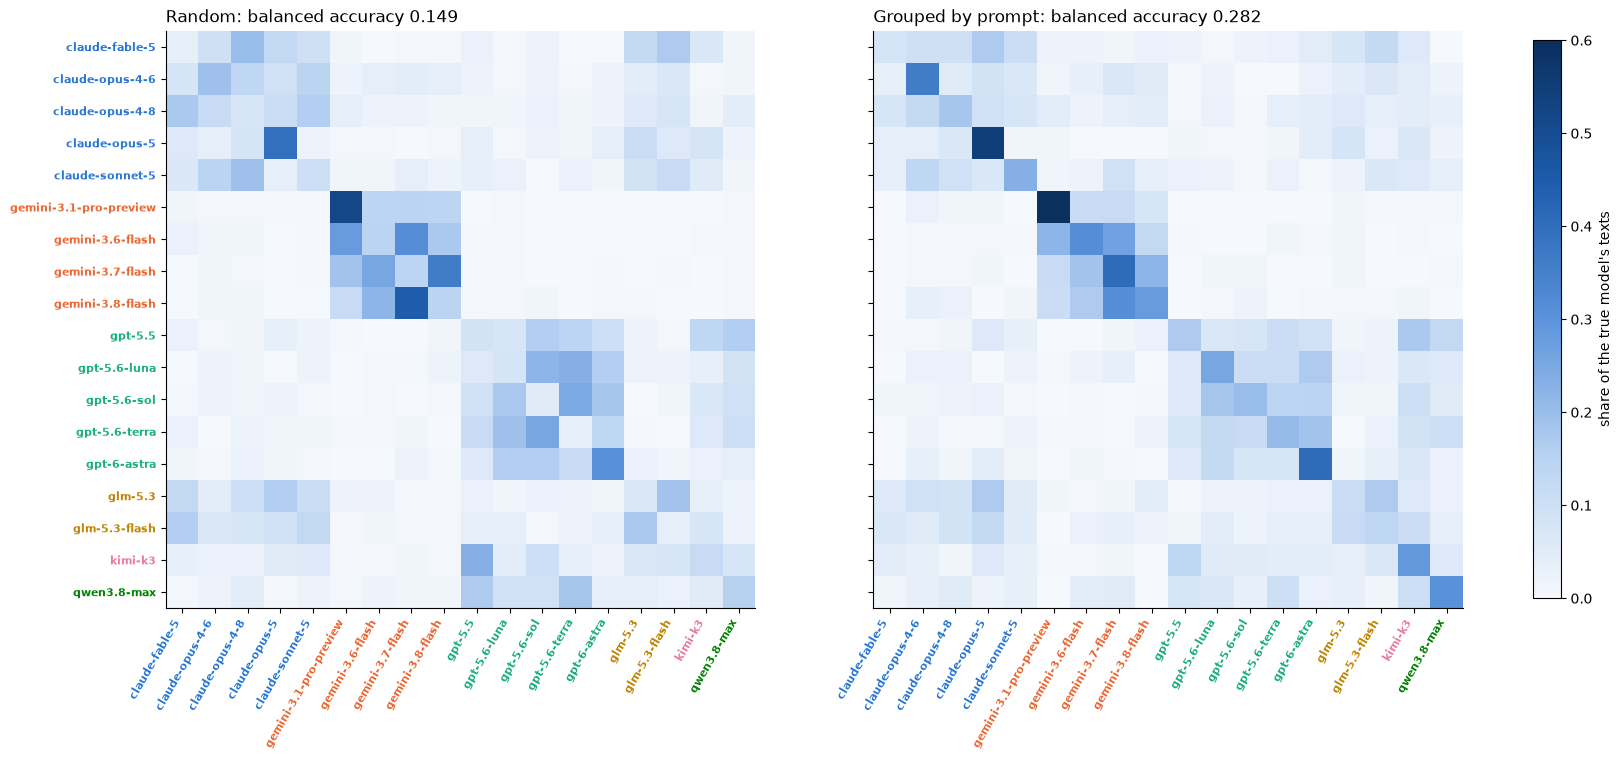

In [3]:
for name in OOF:
    wrong = OOF[name] != y
    print(f"{name:18s} wrong predictions: {wrong.sum()}  of which the predicted model answered the same prompt "
          f"in the training part: {TRAINSEEN[name][wrong].mean():.1%}  (chance if wrong guesses were random: "
          f"{CHANCE[name][wrong].mean():.1%})")
fig, axes = plt.subplots(1, 2, figsize=(18, 7.5), sharey=True)
for ax, name in zip(axes, OOF):
    cm = confusion_matrix(y, OOF[name], labels=MODELS, normalize="true")
    im = ax.imshow(cm, cmap=SEQ, vmin=0, vmax=0.6, aspect="auto")
    ax.set_xticks(range(18), MODELS, rotation=60, ha="right", fontsize=8); ax.set_yticks(range(18), MODELS, fontsize=8)
    colour_labels(ax, "y"); colour_labels(ax, "x")
    ax.set_title(f"{name}: balanced accuracy {balanced_accuracy_score(y, OOF[name]):.3f}", loc="left")
plt.colorbar(im, ax=axes, fraction=0.02, label="share of the true model's texts")
plt.show()

**What this shows:**
- Under the random split, **90.2% of the wrong predictions name a model that answered the same prompt in the training part**, against **66.4%** if wrong guesses were random. Put the other way: a random wrong guess would name a model **not** seen for that prompt 33.6% of the time, the SVM does it only 9.8% of the time, about 3.4 times less. Under the grouped split both numbers are 0% by construction (the prompt is never in training). In the confusion matrices, the random split's diagonal fades and the predictions move mostly to **sibling** cells (gemini-3.8-flash read as 3.7, gemini-3.6 read as 3.7, gpt-5.6 models read as each other): pushed off the true model, the classifier picks the next closest style, which is usually a sibling. The grouped split keeps a clear diagonal.
- That strong tilt supports the explanation in C3: the SVM learns "this prompt's topic means the models I saw for it", and the true author of a validation text is never among them, so the topic votes against the right answer. (It is strong evidence, not a proof; part of the tilt could have other causes, but the size of the drop, 0.282 to 0.149, fits this mechanism.)

**The maths in one line.** For a validation text $x$ of prompt $g$, the score of model $c$ is $w_c \cdot x = w_c \cdot x_{style} + w_c \cdot x_{topic(g)}$. Training pushes $w_c \cdot x_{topic(g)}$ up for every model $c$ that answered $g$ in training and down for the others. The true author $c^*$ is never in that set, so its topic term is pushed down, and a model with a pushed-up topic term wins unless the style evidence is stronger.

**Why it matters to us:** our scores are prompt-grouped (folds split by prompt, plus the simulator), which is the honest version. It is also the same fact that powers "one answer per model per prompt": inside a group of answers to one prompt, each model appears at most once, so evidence for model $c$ on one text is evidence **against** $c$ on the others.

## D. Part II, stage by stage

The order in which a test text travels through their pipeline:

1. **Find groups** of test texts that answer the same prompt (sections 14 and `infer.py`).
2. **Readers** (sections 06, 10 code, `l24_predict`): five LoRA-tuned LLMs + DeBERTa each give 18 log-probabilities per text, plus a **twin** score from prompt-centred features, plus **Gaussian group** scores for two of them (section 09).
3. **Blend** the readers' log-probabilities (average), turn into probabilities, mix in the **complementary stack** (15%) and the **27B GSQ** reader (3%) (sections 13, 15, 16).
4. **Native expert**: Qwen3-Embedding-8B, 5 folds, mixed in at 40% in log space, with **partial Sinkhorn** applied per fold, then averaged (sections 11, 15).
5. Pick the most likely model per text, check the file (section 18).

Sections 07 (find files, unzip archives) and 08 (run two GPU workers at once) are plumbing; they do not change any prediction.

### D1. The LoRA readers (sections 06 and 17, function `l24_predict`)

**What it does:** take a base LLM, keep only its first layers (`keep`: 27 for the Qwen3-14B readers, 24 for Qwen3-8B and Llama; the rest is never run), plug in a trained LoRA adapter, run the text through it, and read the hidden states at 8 depths. For `n14b_clean` and `q25_14` the model's final normalisation layer is replaced by "do nothing" (`no_final_norm`), matching how those adapters were trained.

**The maths:**
- A LoRA adapter changes each big weight matrix $W$ by a small low-rank update: $W' = W + \frac{\alpha}{r} B A$, where $A$ is $r \times d$ and $B$ is $d \times r$ with a small rank $r$ (for example 16). Their code adds $\frac{\alpha}{r} B A$ into $W$ directly ("merging"), runs the texts, then subtracts it again so the next adapter starts from the clean base.
- For each depth $l \in \{2,4,6,8,12,16,20,24\}$ take the hidden states $h_{l,t}$ of every token $t$ (skipping the first token) and **average** them: $\bar h_l = \frac{1}{T}\sum_t h_{l,t}$. Normalise each with its own LayerNorm, and glue the 8 vectors together: $z = [\mathrm{LN}_2(\bar h_2), \dots, \mathrm{LN}_{24}(\bar h_{24})]$.
- A linear head gives 18 scores, turned into log-probabilities: $\log p(c \mid x) = (Wz + b)_c - \log\sum_k e^{(Wz+b)_k}$.
- With several adapters (5 folds + full), the log-probabilities are averaged with weights `aw` (equal unless given, 0.72 / 0.28 for `n14b_clean`).

```python
mask = att.unsqueeze(-1).float(); mask[:, 0] = 0                       # ignore padding and the first token
feat = [nm(((hs[l] * mask).sum(1) / mask.sum(1))) for l, nm in zip(L, norms)]   # mean over tokens, LayerNorm
Z = torch.cat(feat, -1)                                                  # 8 depths glued together
P_acc += lsm(Z @ H['plain.weight'].T + H['plain.bias']) * aw[ai]       # log-softmax of the linear head
```

This is **exactly our `ms` design** (same 8 depths, mean pooling, a head on top). The difference is the size of the base model and that they keep 6 adapters per base instead of 1.

**The twin head** (`centered`): inside each test group, subtract the group's average feature vector, then apply a second head trained on prompt-centred features:
$$z^{c}_i = z_i - \frac{1}{|G|}\sum_{j \in G} z_j$$
Whatever all answers to one prompt share (the topic) is removed before the head looks. It is added only for texts in a group of 2 or more, with weight $0.35 \times$ the reader's weight. We do the same idea one step later, on log-probabilities (our centering 0.25).

### D2. Finding the groups: capped agglomerative clustering (section 14 and `infer.py`)

The hidden test has no prompt ids. To use "these texts answer the same prompt", they must guess the groups.

**The algorithm** (`capped_agglo`, average linkage with a size cap):
1. Start with every text in its own cluster. $S_{ij}$ = similarity of texts $i$ and $j$ (cosine).
2. Repeatedly merge the two clusters with the **highest average similarity**, but only if the merged cluster has **at most 18 texts** (no prompt has more than 18 answers) and the similarity is above a threshold.
3. After a merge, the new cluster's similarity to any other cluster is the size-weighted average: $S_{new,k} = \frac{n_i S_{ik} + n_j S_{jk}}{n_i + n_j}$.
4. Stop when no allowed pair is above the threshold.

First with TF-IDF word vectors (threshold 0.15), then, if it works, with **Qwen3-Embedding-8B** vectors (threshold 0.70), which understand meaning better than word overlap.

Below we run their exact function on 40 prompts of `train.csv` with TF-IDF (we cannot run the 8B embedder on CPU) and measure how pure the clusters are. Purity = share of texts whose cluster's majority prompt is their own prompt.

In [4]:
def capped_agglo(S, cap=18, thr=0.02):   # copied from their infer.py
    n = len(S); A = S.astype(np.float32).copy(); np.fill_diagonal(A, -np.inf)
    size = np.ones(n, np.int32); alive = np.ones(n, bool); lab = np.arange(n)
    while True:
        ok = (size[:, None] + size[None, :] <= cap) & alive[:, None] & alive[None, :]
        M = np.where(ok, A, -np.inf); k = int(np.argmax(M)); i, j = divmod(k, n)
        if not np.isfinite(M[i, j]) or M[i, j] < thr: break
        new = (size[i] * A[i] + size[j] * A[j]) / (size[i] + size[j])
        A[i] = new; A[:, i] = new; A[i, i] = -np.inf; A[j] = -np.inf; A[:, j] = -np.inf
        size[i] += size[j]; alive[j] = False; lab[lab == j] = i
    return lab

rng = np.random.default_rng(0)
sub = train[train.prompt_id.isin(rng.choice(train.prompt_id.unique(), 40, replace=False))].reset_index(drop=True)
X = TfidfVectorizer(sublinear_tf=True, stop_words="english", min_df=2, max_df=0.05).fit_transform(sub.text)
S = (X @ X.T).toarray()
def purity(lab, truth):
    d = pd.DataFrame({"c": lab, "p": truth})
    maj = d.groupby("c").p.agg(lambda s: s.value_counts().index[0])
    return float((d.p == d.c.map(maj)).mean())
rows = []
for thr in [0.05, 0.10, 0.15, 0.20, 0.30]:
    lab = capped_agglo(S, 18, thr)
    sizes = np.bincount(lab)[np.unique(lab)]
    rows.append({"threshold": thr, "clusters": len(sizes), "mean size": sizes.mean(), "singletons": int((sizes == 1).sum()),
                 "purity": purity(lab, sub.prompt_id.values)})
G = pd.DataFrame(rows)
print(f"{len(sub)} texts from 40 prompts (true clusters: 40 of about 18)")
print(G.round(3).to_string(index=False))

720 texts from 40 prompts (true clusters: 40 of about 18)
 threshold  clusters  mean size  singletons  purity
      0.05        42     17.143           1     1.0
      0.10        67     10.746          13     1.0
      0.15       122      5.902          37     1.0
      0.20       230      3.130         122     1.0
      0.30       511      1.409         393     1.0


**What this shows:**
- On these 40 training prompts, the clusters are **100% pure at every threshold**: their algorithm never puts answers to two different prompts together. Training prompts have very distinct topics, and the cap of 18 stops runaway clusters.
- The threshold trades off **completeness**: at 0.05 it finds 42 clusters for 40 prompts (almost perfect); at their TF-IDF setting 0.15 a prompt's 18 answers are split into about 3 smaller clusters (mean size 5.9, 37 texts alone). Splitting keeps the one-per-model rule true (a sub-group of one prompt still has each model at most once) but makes it weaker, and it makes the centring noisier (the mean of 3 texts estimates the topic worse than the mean of 18). Mixing prompts would be actively harmful. Note that purity is automatically 1.0 for a text alone, so at high thresholds (393 of 511 clusters are single texts at 0.30) the purity number says little.
- **Caution:** 40 hand-picked prompts with 18 answers each is the easy case. The hidden test has many more prompts (we estimated about 4 answers per prompt), so topics overlap more and purity will be lower; that is why they switch to the Qwen3-Embedding-8B similarity (threshold 0.70) when it is available.

### D3. The Gaussian group readout (section 09): the most mathematical part

**The idea in words:** a text's features = **who wrote it** + **what prompt it answers** + noise. If several test texts answer the same prompt, they share the prompt part. Looking at them together lets you cancel the shared prompt part, and you can also use the rule that **one model answers a prompt only once**.

**The model** (fitted on train features $x$ of a reader, after a PCA that removes prompt means first):
$$x_i = \mu_{c_i} + p_{g_i} + e_i, \qquad p_g \sim N(0, \Sigma_p), \qquad e_i \sim N(0, \Sigma_e)$$
- $\mu_c$: the average style of model $c$
- $p_g$: the shift caused by prompt $g$ (topic), shared by all its answers
- $e_i$: everything else

`_two_way` estimates $\mu$ and $p$ by alternating (class means of $x - p$, then prompt means of $x - \mu$). $\Sigma_e$ and $\Sigma_p$ are the covariances of the leftovers, shrunk toward a multiple of the identity (Ledoit-Wolf) because there are few samples per dimension.

**Whitening:** they transform the space so that $\Sigma_e$ becomes the identity and $\Sigma_p$ becomes diagonal with values $\lambda_d$ ("how strong the prompt shift is along direction $d$, compared with noise"). Then everything works dimension by dimension.

**One text alone** (the prompt shift is unknown, so it is just more noise): with $r = u - m_c$ the distance to model $c$'s mean,
$$\log p(u \mid c) = -\tfrac12 \sum_d \frac{r_d^2}{1 + \lambda_d} + \text{const}$$
That is `singleton_ll`. Directions where prompts shift a lot (large $\lambda$) are trusted less.

**A group of $n$ texts with one shared prompt shift.** Integrating out the shared $p$ gives, per dimension (with $\gamma = \frac{\lambda}{1 + n\lambda}$):
$$\log p(u_1..u_n \mid c_1..c_n) = -\tfrac12 \sum_d \Big[ \sum_i r_{i,d}^2 - \gamma_d \big(\textstyle\sum_i r_{i,d}\big)^2 \Big] + \text{const}$$
The second term rewards assignments whose residuals **point the same way**, because a shared shift explains them. That is `joint_terms` (the $a$ and $B$ terms are this expanded into single and pair terms).

**One answer per model per prompt** (`inj=True`): for groups of up to 3 texts they enumerate **every** assignment of distinct models ($18 \times 17 \times 16$ for 3 texts), set the forbidden ones (two texts with the same model) to $-\infty$, and sum to get each text's probability for each model (`exact_marginals`). For bigger groups this is too many combinations, so they use an approximation (`em_marginals`) with a "repel" term $\sum_{j \ne i} \log(1 - q_j(c))$ that lowers model $c$ for text $i$ when other texts in the group are probably $c$. **That repel term is the same "mean-field exclusion" we tested on our simulator** (it did not pass there).

**How it is used at 0.684:** fitted while the notebook runs on the train features of `q14v5` and `q8v5` (PCA to 128 dimensions after removing prompt means), with temperature 3.0 (all log-likelihoods divided by 3, which softens them). It is applied **only to test texts in a group of 2 to 18**; other texts get 0 from this term. Its weight (0.70 and 0.44) is not multiplied by the reader's weight.

The toy below generates data from exactly this model (6 models, groups of 4 answers to one prompt) and compares: one text at a time; the group model without the one-per-model rule; and with it. Then it breaks the groups (merges two prompts into one "group") to show what happens when the clustering is wrong.

In [5]:
def simulate(n_prompts=400, K=6, D=12, n=4, prompt_sd=1.5, seed=0):
    r = np.random.default_rng(seed)
    mu = r.normal(0, 1.0, (K, D))
    X, Y, Gp = [], [], []
    for g in range(n_prompts):
        cls = r.choice(K, n, replace=False)                 # n different models answer this prompt
        p = r.normal(0, prompt_sd, D)                        # the prompt's shared shift
        for c in cls:
            X.append(mu[c] + p + r.normal(0, 1, D)); Y.append(c); Gp.append(g)
    return np.array(X), np.array(Y), np.array(Gp), mu

def group_scores(U, mu, lam, inj):
    """exact joint posterior of one group in whitened units (noise sd 1, prompt variance lam per dim)"""
    n, K = len(U), len(mu)
    gam = lam / (1 + n * lam)
    best = np.full((n, K), -np.inf)
    combos = itertools.permutations(range(K), n) if inj else itertools.product(range(K), repeat=n)
    logs = []; assigns = []
    for a in combos:
        R = U - mu[list(a)]
        logs.append(-0.5 * ((R ** 2).sum() - (gam * R.sum(0) ** 2).sum())); assigns.append(a)
    logs = np.array(logs); w = np.exp(logs - logs.max()); w /= w.sum()
    P = np.zeros((n, K))
    for wt, a in zip(w, assigns):
        P[np.arange(n), a] += wt
    return P

def evaluate(prompt_sd):
    X, Y, Gp, mu = simulate(prompt_sd=prompt_sd)
    lam = np.full(X.shape[1], prompt_sd ** 2)
    single = (-0.5 * (((X[:, None, :] - mu[None]) ** 2) / (1 + lam)).sum(-1)).argmax(1)
    out = {}
    for inj in (False, True):
        pred = np.empty(len(Y), int)
        for g in np.unique(Gp):
            ii = np.where(Gp == g)[0]
            pred[ii] = group_scores(X[ii], mu, lam, inj).argmax(1)
        out[inj] = (pred == Y).mean()
    return (single == Y).mean(), out[False], out[True]

rows = []
for sd in [0.0, 0.5, 1.0, 1.5, 2.5]:
    a, b, c = evaluate(sd)
    rows.append({"prompt shift sd": sd, "one text at a time": a, "group, no one-per-model rule": b,
                 "group + one-per-model rule": c})
T = pd.DataFrame(rows).set_index("prompt shift sd")
print("accuracy on toy data (6 models, 4 answers per prompt, groups known):")
print(T.round(3).to_string())

accuracy on toy data (6 models, 4 answers per prompt, groups known):
                 one text at a time  group, no one-per-model rule  group + one-per-model rule
prompt shift sd                                                                              
0.0                           0.910                         0.910                       0.949
0.5                           0.874                         0.898                       0.942
1.0                           0.779                         0.888                       0.934
1.5                           0.655                         0.888                       0.932
2.5                           0.486                         0.884                       0.931


**What this shows (toy data built exactly like their model):**
- **One text at a time** gets worse as the prompt shift grows (0.91 to 0.49): the topic drowns the style.
- **Looking at the group** cancels the shared shift: about 0.89 whatever its size.
- **Adding the one-per-model rule** adds another 3 to 5 points (0.93 to 0.95), even when there is no prompt shift at all, because knowing that the other three texts are "probably claude, gpt, kimi" removes those options for the fourth.

In [6]:
# what if the groups are wrong? merge pairs of prompts into one "group" of 8 texts (the rule is then false)
X, Y, Gp, mu = simulate(prompt_sd=1.5)
lam = np.full(X.shape[1], 1.5 ** 2)
right, merged = [], []
for g in range(0, 400, 2):
    a_, b_ = np.where(Gp == g)[0], np.where(Gp == g + 1)[0]
    for ii in (a_, b_):
        right.append((group_scores(X[ii], mu, lam, True).argmax(1) == Y[ii]).mean())
    both = np.r_[a_, b_]
    # treat the 8 texts as two fake groups of 4 chosen by order: half of each fake group is from the other prompt
    fake = [np.r_[a_[:2], b_[:2]], np.r_[a_[2:], b_[2:]]]
    for ii in fake:
        merged.append((group_scores(X[ii], mu, lam, True).argmax(1) == Y[ii]).mean())
single = (-0.5 * (((X[:, None, :] - mu[None]) ** 2) / (1 + lam)).sum(-1)).argmax(1)
print(f"one text at a time:                  {(single == Y).mean():.3f}")
print(f"group + rule, correct groups:        {np.mean(right):.3f}")
print(f"group + rule, groups half wrong:     {np.mean(merged):.3f}")

one text at a time:                  0.655
group + rule, correct groups:        0.932
group + rule, groups half wrong:     0.677


**What this shows:** when half of each group is from another prompt, the gain almost disappears (0.68 vs 0.66 alone, vs 0.93 with correct groups): the shared-shift assumption and the one-per-model rule are both false for a mixed group. **The method is only as good as the groups.** This is the toy version of what our LB probe P1 showed (hard one-per-model assignment inside our TF-IDF clusters: -3.5), and why their pipeline puts effort into grouping (Qwen3-Embedding cosine, cap 18).

### D4. Blending and partial Sinkhorn (section 15, functions `blend` and `decide_scores`)

**Blend.** Every reader term (plain, twin, Gaussian) is a matrix of log-probabilities already multiplied by its weight. `blend` sums them and divides by the number of active terms (`sk_div=1`), then turns the result into probabilities:
$$\ell_{ic} = \frac{1}{A}\sum_{t} w_t \log p_t(c \mid x_i), \qquad P_{ic} = \frac{e^{\ell_{ic}}}{\sum_k e^{\ell_{ik}}}$$
Here $A$ is the **number** of active terms, not the sum of their weights (the weights add up to much more than $A$), so this is not exactly a weighted geometric mean; it behaves like one at a lower temperature (sharper). The practical effect is the same: because log-probabilities are added, a model gets a high final score only if most readers like it. Then the complementary stack is mixed in probability space: $P \leftarrow 0.85\,P + 0.15\,P_{comp}$, and later the 27B GSQ: $P \leftarrow 0.97\,P + 0.03\,P_{27B}$.

**Sinkhorn.** The metric is balanced accuracy, so predicting too many texts as one model hurts. Sinkhorn rescales the probability table so that every column (model) gets a chosen total:
1. multiply each column $c$ by $\frac{N \cdot t_c}{\sum_i Q_{ic}}$ (make column totals match the target $t$)
2. divide each row by its sum (each text's probabilities sum to 1 again)
3. repeat (they do 100 rounds)

**Their two twists:**
- **target mix**: the target is not uniform. $t = 0.65 \cdot \bar P + 0.35 \cdot \pi_{train}$, where $\bar P$ is the current average prediction and $\pi_{train}$ the class shares in `train.csv` (almost uniform). So they only pull 35% of the way toward balance.
- **partial**: the final score is $0.70 \log P + 0.30 \log Q$, only part of the way to the balanced table.

We use the same partial idea (0.45) with a uniform target.

**Native expert** (last step, `native_stage`): for each of the 5 folds of the Qwen3-Embedding-8B expert, mix in log space $\log P' = 0.60 \log P + 0.40 \log P_{native,k}$, apply the partial Sinkhorn, softmax; then average the 5 folds and take the top model.

Below: a toy table with a skewed reader, before and after full and partial Sinkhorn.

In [7]:
def sinkhorn_partial(P, strength, target_mix, prior):
    Q = P.copy()
    marg = P.mean(0); marg /= marg.sum()
    t = (1 - target_mix) * marg + target_mix * prior; t /= t.sum()
    for _ in range(100):
        Q *= (len(Q) * t[None, :]) / Q.sum(0, keepdims=True)
        Q /= Q.sum(1, keepdims=True)
    return (1 - strength) * np.log(P + 1e-12) + strength * np.log(Q + 1e-12)

r = np.random.default_rng(1)
K, N = 6, 600
truth = np.repeat(np.arange(K), N // K)
logit = r.normal(0, 1, (N, K)); logit[np.arange(N), truth] += 1.2; logit[:, 0] += 0.9   # reader too fond of model 0
P = np.exp(logit); P /= P.sum(1, keepdims=True)
prior = np.full(K, 1 / K)
for name, s, m in [("no balancing", 0.0, 0.0), ("theirs: 0.30, target mix 0.35", 0.30, 0.35),
                   ("ours: 0.45, uniform target", 0.45, 1.0), ("full Sinkhorn, uniform", 1.0, 1.0)]:
    pred = sinkhorn_partial(P, s, m, prior).argmax(1)
    share = np.bincount(pred, minlength=K) / N
    bacc = np.mean([(pred[truth == c] == c).mean() for c in range(K)])
    print(f"{name:32s} predicted share of model 0: {share[0]:.2f} (true 0.17)  balanced accuracy {bacc:.3f}")

no balancing                     predicted share of model 0: 0.41 (true 0.17)  balanced accuracy 0.450
theirs: 0.30, target mix 0.35    predicted share of model 0: 0.36 (true 0.17)  balanced accuracy 0.457
ours: 0.45, uniform target       predicted share of model 0: 0.28 (true 0.17)  balanced accuracy 0.477
full Sinkhorn, uniform           predicted share of model 0: 0.17 (true 0.17)  balanced accuracy 0.490


**What this shows (toy):** a reader that over-predicts model 0 (41% instead of 17%). Their gentle setting (0.30 strength, 35% target pull) only moves it to 36%; our 0.45 to a uniform target to 28%; full Sinkhorn to the true 17%. On this toy, more balancing is better because the bias is pure. On real data the right strength depends on how wrong the readers' class shares are and how reliable the probabilities are: they tuned 0.30 / 0.35 on the LB with a stack of strong readers; we chose 0.45 with our simulator for our weaker stack. Neither number transfers automatically to the other pipeline.

### D5. The other stages

| Section | Stage | What it does | Used at 0.684? |
|---|---|---|---|
| 07 | Evidence locker | finds the model folders on disk, glues a split zip archive back together and checks its contents; also writes an Open Pool sample drawn by `match_weight`, which the 0.684 command does **not** pass on to `infer.py` | yes (setup) |
| 07 | `FAST_COMMIT` | the public `test.csv` has 3 rows; if fewer than 50, it writes a dummy answer quickly; the real run happens when Kaggle re-runs it on the hidden test | yes (we do the same) |
| 08 | Pipelined workers | runs two copies of a model on two GPUs in parallel after checking both give the same numbers | yes (speed only) |
| 10 | Their ATLAS | a language model with one LoRA "voice" per author: scores how likely the text is under each author's voice (generative classification). **Not the same as our ATLAS**, which is token statistics of the plain base model fed to LightGBM | **no** (`atlas_mode` stays `off`) |
| 11 | Native Qwen3-Embedding-8B | 5 trained fold heads on multi-depth features of an embedding model, each with its own calibration file; plain and prompt-centred outputs | yes, 40% |
| 12 | Sparse prefit | LinearSVC / TF-IDF / "distort" scores from a prefit archive | **no** (weights 0) |
| 13 | GSQ 27B | a quantised Qwen3.8-27B with its own classifier | yes, 3% |
| 16 | Complementary stack | a second ensemble with its own blend (weights `W` in `comp_stack.py`): **stylegram** 1.516 (a LinearSVC on style n-grams, fitted at run time on train.csv + Open Pool prompts with 12+ models, plain for single texts and prompt-centred for grouped texts) dominates; then several LoRA readers (0.11 to 0.18 each), token-attention heads (0.15 to 0.19), encoders (DeBERTa 0.05, ELECTRA 0.03, desklib 0.13, ultrabert 0.10), a stylometry LightGBM (0.06), Gaussian heads and "family gates" | yes, 15% |
| 18 | Integrity | checks the submission has every id once and two columns | yes |

## E. What this means for us

1. **The gap is mostly model size and number of readers, not a trick.** Their reader design is ours; their post-processing ideas (grouping, prompt centring, one-per-model, partial Sinkhorn) are close to what we already use. What we lack is several 8B to 27B readers, each averaged over 6 fits, plus a strong embedding expert.
2. **Section 05 explains our own "known data" worry from the other side.** A random split misleads in both directions here; prompt-grouped CV (what we use, plus the simulator) is the honest choice.
3. **Their one-per-model Gaussian group model** is the principled version of the exclusion idea we rejected. It works in their stack with groups from a strong embedder (cosine 0.70, capped at 18). Our TF-IDF groups are less pure, which is why the rule hurt us (toy D3: wrong groups make it harmful).
4. **All their weights are public.** A notebook that attaches the same public datasets reproduces 0.684 without training. Whether to build on public weights is your decision (it changes what "our" solution is, and the competition's rules on public assets apply equally to everyone).